# 02 — Article Figures

This notebook produces all publication-quality figures for:

> **Performing Europe Through Lexicography: A Multilingual Computational Analysis of Music, Dance, and Sonic Culture in Nineteenth-Century Historical Dictionaries**

Figures are saved to `../visualizations/` and referenced in `../reports/article_draft.md`.

Dataset: `../datasets/master_performance_dataset_v3.csv` (3,067 entries, 22 fields)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import Counter

# ── Output directory ──────────────────────────────────────────────────────────
FIG_DIR = '../visualizations'
os.makedirs(FIG_DIR, exist_ok=True)

# ── Publication style ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ── Colour palettes ───────────────────────────────────────────────────────────
CAT_PALETTE = {
    'PERFORMANCE':    '#2C5F8A',
    'INSTRUMENTS':    '#4A90A4',
    'VOICE':          '#6AAB9C',
    'MUSIC_CONCEPTS': '#A8D5BA',
    'SOUND':          '#D4A96A',
    'DANCE':          '#C0504D',
}
DICT_COLORS = {
    'Complete Encyclopaedia of Music':                       '#2C5F8A',
    'A Dictionary of Music and Musicians (A.D. 1450-1889)':  '#6AAB9C',
    'Musik-Lexikon':                                          '#C0504D',
}
DICT_SHORT = {
    'Complete Encyclopaedia of Music':                       'Moore (1854)',
    'A Dictionary of Music and Musicians (A.D. 1450-1889)':  'Grove (1879)',
    'Musik-Lexikon':                                          'Riemann (1882)',
}

print('Setup complete.')

Setup complete.


In [2]:
df = pd.read_csv('../datasets/master_performance_dataset_v3.csv')
df['dict_short'] = df['source_dictionary'].map(DICT_SHORT)
print(f'Loaded {len(df):,} entries from {df["source_dictionary"].nunique()} dictionaries.')
df.head(2)

Loaded 3,067 entries from 5 dictionaries.


,id,language,headword,normalized_headword,category,subcategory,definition,example,etymology,source_dictionary,...,page,source_text,semantic_tags,geographic_refs,historical_refs,cross_refs,confidence_score,multilingual_alignment,notes,dict_short
0,EN-MOORE-1854-00003,English,A ABOVK G GAMUT,a abovk g gamut,SOUND,QUALITY,"That A, or that note, which !• one tone",NaN,NaN,Complete Encyclopaedia of Music,...,NaN,"A ABOVK G GAMUT. That A, or that note,...",Neutral,NaN,NaN,NaN,0.000,NaN,NaN,Moore (1854)
1,EN-MOORE-1854-00004,English,A ABOVE THE BASS CLEF NOTE,a above the bass clef note,VOICE,VOICE_TYPE,"That A, or that note,",NaN,NaN,Complete Encyclopaedia of Music,...,NaN,"A ABOVE THE BASS CLEF NOTE. That A, or...",Neutral,NaN,NaN,NaN,0.053,NaN,NaN,Moore (1854)


---
## Figure 1 — Category Distribution

**Article reference:** Section 5.1, Table 1

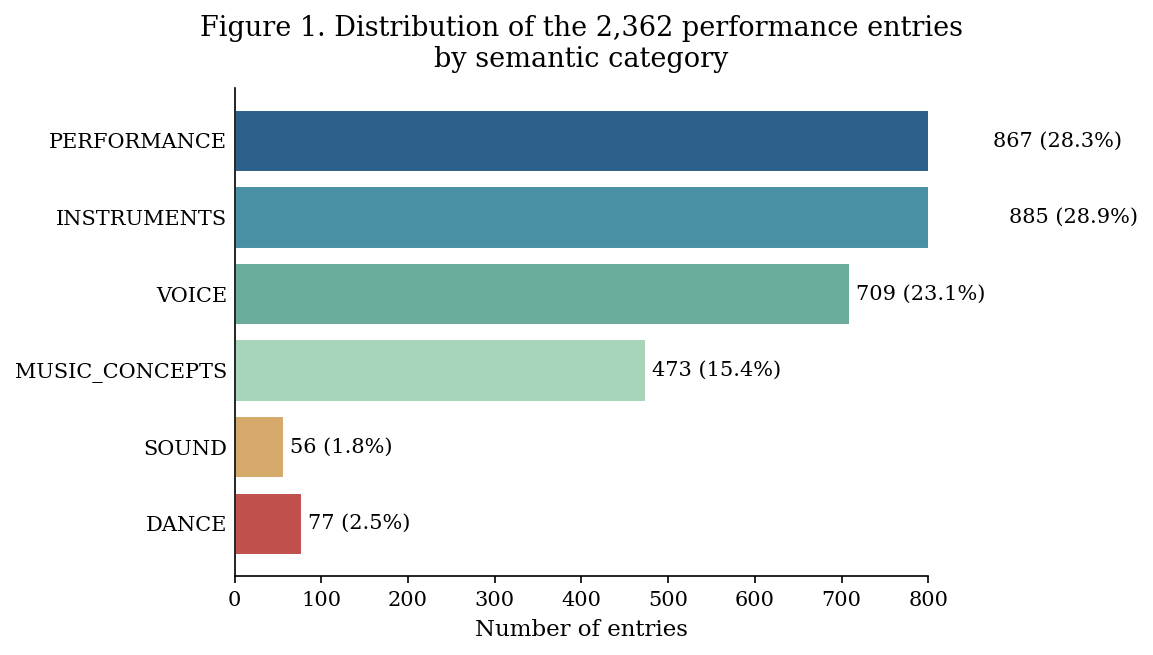

Saved fig1_category_distribution.png


In [3]:
cat_order = ['PERFORMANCE', 'INSTRUMENTS', 'VOICE', 'MUSIC_CONCEPTS', 'SOUND', 'DANCE']
cat_counts = df['category'].value_counts().reindex(cat_order)
cat_pct    = (cat_counts / cat_counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(
    cat_order[::-1],
    cat_counts.values[::-1],
    color=[CAT_PALETTE[c] for c in cat_order[::-1]],
    edgecolor='white', linewidth=0.5
)

for bar, n, p in zip(bars, cat_counts.values[::-1], cat_pct.values[::-1]):
    ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
            f'{n:,} ({p}%)', va='center', fontsize=10)

ax.set_xlabel('Number of entries')
ax.set_title('Figure 1. Distribution of the 2,362 performance entries\nby semantic category', pad=10)
ax.set_xlim(0, 800)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig1_category_distribution.png')
plt.show()
print('Saved fig1_category_distribution.png')

---
## Figure 2 — Cross-Dictionary Category Comparison

**Article reference:** Section 5.7

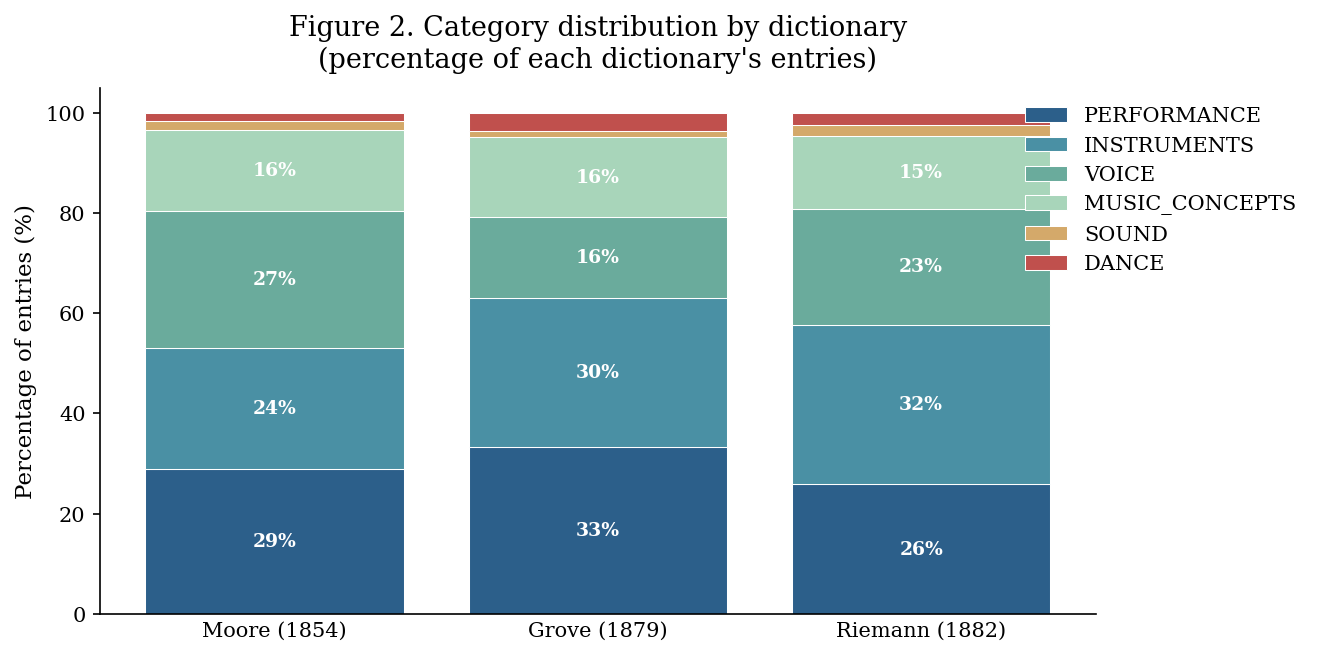

Saved fig2_cross_dictionary_categories.png


In [4]:
cross = (
    df.groupby(['dict_short', 'category'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=cat_order)
)
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

dict_order = ['Moore (1854)', 'Grove (1879)', 'Riemann (1882)']
cross_pct = cross_pct.reindex(dict_order)

fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(dict_order))
for cat in cat_order:
    vals = cross_pct[cat].values
    bars = ax.bar(dict_order, vals, bottom=bottom,
                  color=CAT_PALETTE[cat], label=cat, edgecolor='white', linewidth=0.5)
    for b, v, bt in zip(bars, vals, bottom):
        if v > 4:
            ax.text(b.get_x() + b.get_width() / 2, bt + v / 2,
                    f'{v:.0f}%', ha='center', va='center', fontsize=9,
                    color='white', fontweight='bold')
    bottom += vals

ax.set_ylabel('Percentage of entries (%)')
ax.set_ylim(0, 105)
ax.set_title('Figure 2. Category distribution by dictionary\n(percentage of each dictionary\'s entries)', pad=10)
ax.legend(loc='upper right', bbox_to_anchor=(1.22, 1), frameon=False)
ax.tick_params(axis='x', length=0)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig2_cross_dictionary_categories.png')
plt.show()
print('Saved fig2_cross_dictionary_categories.png')

---
## Figure 3 — Sacred vs. Theatrical Framing by Dictionary

**Article reference:** Section 5.2

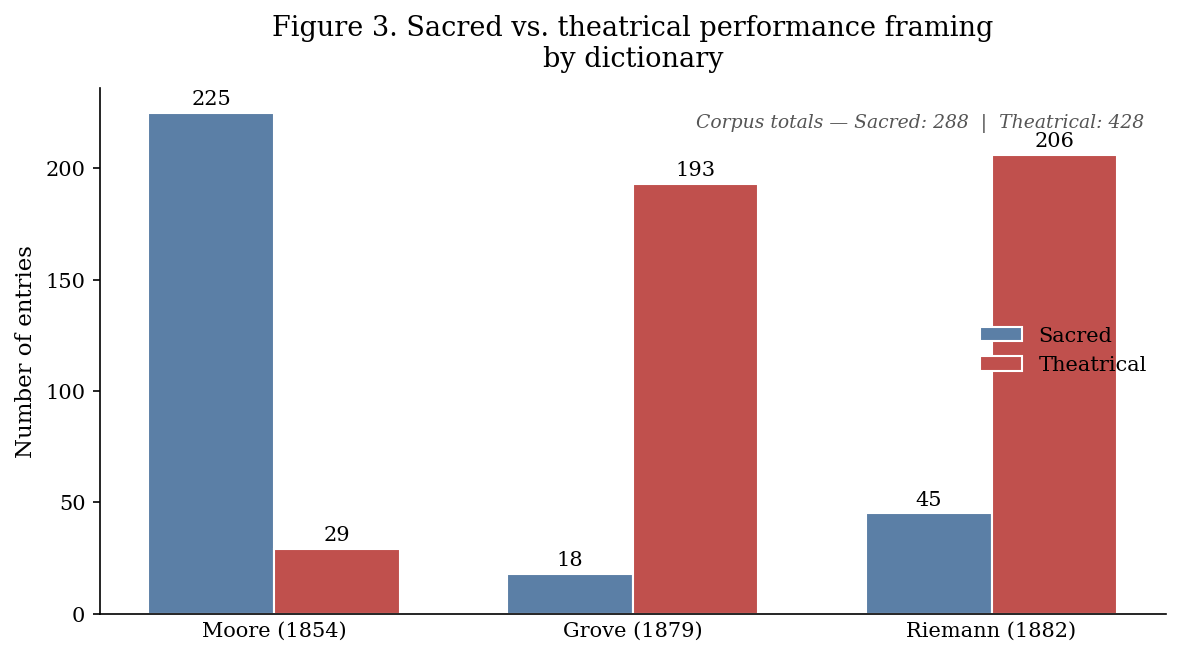

Saved fig3_sacred_theatrical.png


In [5]:
perf_df = df[df['category'] == 'PERFORMANCE'].copy()
sacred_theatrical = perf_df[perf_df['subcategory'].isin(['SACRED', 'THEATRICAL'])]

pivot = (
    sacred_theatrical.groupby(['dict_short', 'subcategory'])
    .size()
    .unstack(fill_value=0)
    .reindex(dict_order)
)

x = np.arange(len(dict_order))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_s = ax.bar(x - width/2, pivot['SACRED'],    width, label='Sacred',     color='#5B7FA6', edgecolor='white')
bars_t = ax.bar(x + width/2, pivot['THEATRICAL'], width, label='Theatrical', color='#C0504D', edgecolor='white')

for bar in list(bars_s) + list(bars_t):
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 2, str(int(h)),
                ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(dict_order)
ax.set_ylabel('Number of entries')
ax.set_title('Figure 3. Sacred vs. theatrical performance framing\nby dictionary', pad=10)
ax.legend(frameon=False)
ax.tick_params(axis='x', length=0)

# Totals annotation
total_s = pivot['SACRED'].sum()
total_t = pivot['THEATRICAL'].sum()
ax.text(0.98, 0.95,
        f'Corpus totals — Sacred: {total_s}  |  Theatrical: {total_t}',
        transform=ax.transAxes, ha='right', va='top',
        fontsize=9, style='italic', color='#555555')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig3_sacred_theatrical.png')
plt.show()
print('Saved fig3_sacred_theatrical.png')

---
## Figure 4 — Geographic References

**Article reference:** Section 5.4

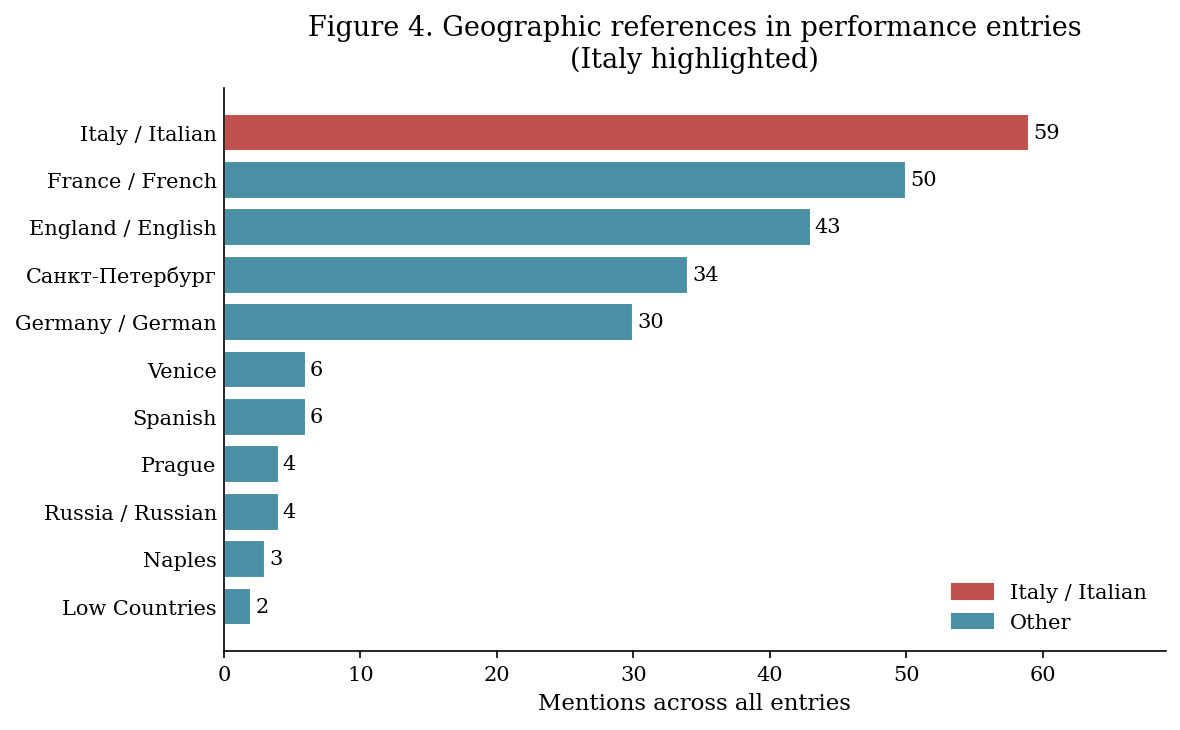

Saved fig4_geographic_references.png


In [6]:
# Expand multi-value geographic_refs cells
geo_all = []
for val in df['geographic_refs'].dropna():
    for g in str(val).split(';'):
        geo_all.append(g.strip())

# Normalise country/city labels to high-level groups
geo_map = {
    'Italian': 'Italy / Italian', 'Italy': 'Italy / Italian',
    'French': 'France / French', 'French; Italian': 'France / French',
    'France; Paris': 'France / French', 'Paris': 'France / French',
    'English': 'England / English', 'England': 'England / English',
    'London': 'England / English',
    'German': 'Germany / German', 'Vienna': 'Germany / German',
    'Berlin': 'Germany / German',
    'Venice': 'Venice',
    'Prague': 'Prague',
    'Russia': 'Russia / Russian', 'Russian': 'Russia / Russian',
    'Italian; Spanish': 'Spain / Spanish', 'Warsaw': 'Poland',
    'Ghent': 'Low Countries', 'Flanders': 'Low Countries',
}
geo_norm = [geo_map.get(g, g) for g in geo_all if g != 'nan']
geo_counts = pd.Series(Counter(geo_norm)).sort_values(ascending=True)
# Keep only groups with >= 2 mentions
geo_counts = geo_counts[geo_counts >= 2]

# Colour: Italy in accent, others in sequential grey-blue
colors = ['#C0504D' if 'Italy' in l else '#4A90A4' for l in geo_counts.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(geo_counts.index, geo_counts.values, color=colors, edgecolor='white')
for bar in bars:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            str(int(bar.get_width())), va='center', fontsize=10)

ax.set_xlabel('Mentions across all entries')
ax.set_title('Figure 4. Geographic references in performance entries\n(Italy highlighted)', pad=10)
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, geo_counts.max() + 10)

italy_patch = mpatches.Patch(color='#C0504D', label='Italy / Italian')
other_patch = mpatches.Patch(color='#4A90A4', label='Other')
ax.legend(handles=[italy_patch, other_patch], frameon=False, loc='lower right')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig4_geographic_references.png')
plt.show()
print('Saved fig4_geographic_references.png')

---
## Figure 5 — Instrument Families

**Article reference:** Section 5.3

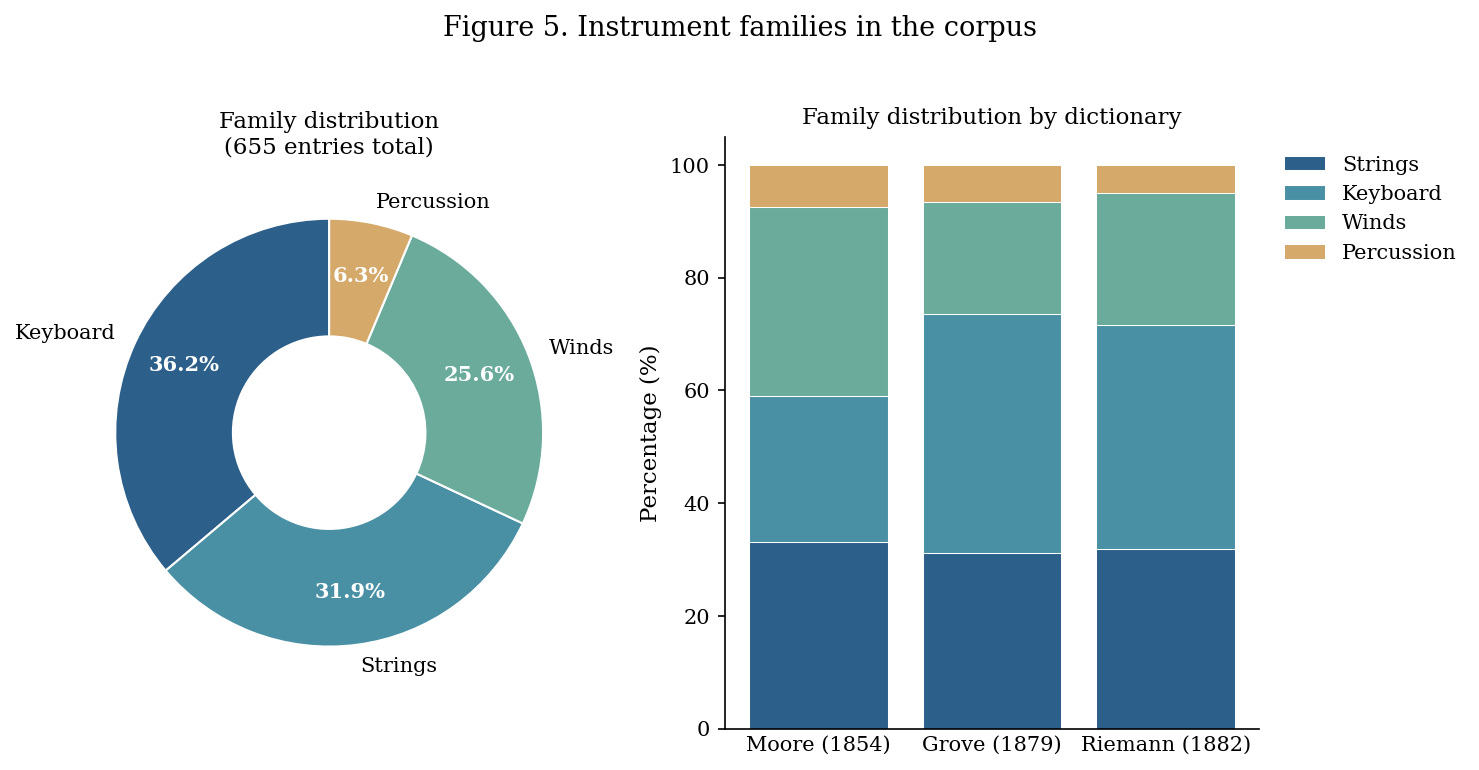

Saved fig5_instrument_families.png


In [7]:
inst_df = df[df['category'] == 'INSTRUMENTS']
fam_counts = inst_df['subcategory'].value_counts()

fam_label_map = {
    'STRINGS': 'Strings', 'KEYBOARD': 'Keyboard',
    'WINDS': 'Winds', 'PERCUSSION': 'Percussion',
}
fam_counts.index = [fam_label_map.get(i, i) for i in fam_counts.index]

family_colors = ['#2C5F8A', '#4A90A4', '#6AAB9C', '#D4A96A']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Donut
wedges, texts, autotexts = ax1.pie(
    fam_counts.values,
    labels=fam_counts.index,
    autopct='%1.1f%%',
    colors=family_colors,
    startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='white'),
    pctdistance=0.75,
)
for t in autotexts:
    t.set_fontsize(10)
    t.set_fontweight('bold')
    t.set_color('white')
ax1.set_title('Family distribution\n(655 entries total)', fontsize=11)

# By-dictionary family breakdown (stacked bar)
inst_cross = (
    inst_df.assign(family=inst_df['subcategory'].map(fam_label_map))
           .groupby(['dict_short', 'family']).size()
           .unstack(fill_value=0)
           .reindex(dict_order)
)
inst_cross_pct = inst_cross.div(inst_cross.sum(axis=1), axis=0) * 100

bottom = np.zeros(len(dict_order))
for fam, col in zip(['Strings', 'Keyboard', 'Winds', 'Percussion'], family_colors):
    if fam in inst_cross_pct.columns:
        vals = inst_cross_pct[fam].values
        ax2.bar(dict_order, vals, bottom=bottom, color=col, label=fam,
                edgecolor='white', linewidth=0.5)
        bottom += vals

ax2.set_ylabel('Percentage (%)')
ax2.set_ylim(0, 105)
ax2.set_title('Family distribution by dictionary', fontsize=11)
ax2.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.tick_params(axis='x', length=0)

fig.suptitle('Figure 5. Instrument families in the corpus', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig5_instrument_families.png')
plt.show()
print('Saved fig5_instrument_families.png')

---
## Figure 6 — Semantic Tag Distribution

**Article reference:** Sections 5.2, 6.2

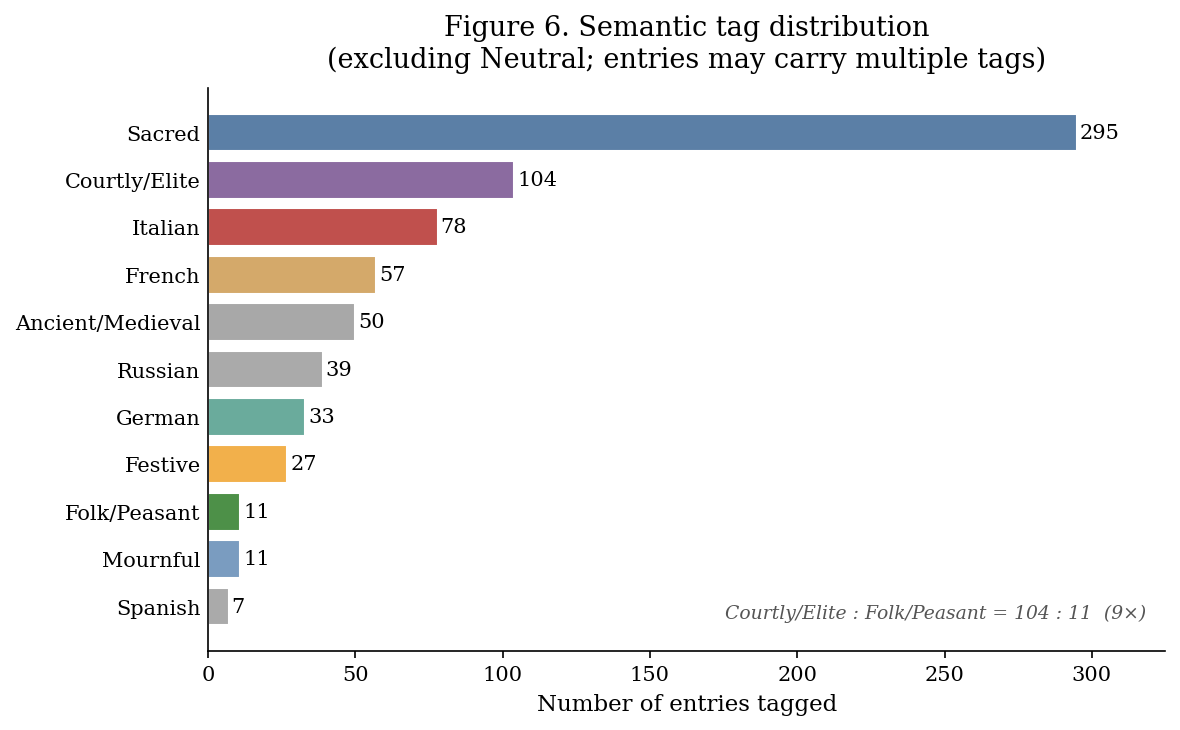

Saved fig6_semantic_tags.png


In [8]:
# Expand multi-tag cells
tags_all = []
for val in df['semantic_tags'].dropna():
    for t in str(val).split(';'):
        t = t.strip()
        if t and t != 'Neutral':
            tags_all.append(t)

tag_counts = pd.Series(Counter(tags_all)).sort_values(ascending=True)

tag_palette = {
    'Sacred': '#5B7FA6',
    'Courtly/Elite': '#8B6BA0',
    'Italian': '#C0504D',
    'French': '#D4A96A',
    'German': '#6AAB9C',
    'Ancient/Medieval': '#A8A8A8',
    'Festive': '#F2B04B',
    'Mournful': '#7A9CC0',
    'Folk/Peasant': '#4D9048',
}
colors = [tag_palette.get(t, '#AAAAAA') for t in tag_counts.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(tag_counts.index, tag_counts.values, color=colors, edgecolor='white')
for bar in bars:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            str(int(bar.get_width())), va='center', fontsize=10)

ax.set_xlabel('Number of entries tagged')
ax.set_title('Figure 6. Semantic tag distribution\n(excluding Neutral; entries may carry multiple tags)', pad=10)
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, tag_counts.max() + 30)

# Ratio annotation
elite = tag_counts.get('Courtly/Elite', 0)
folk  = tag_counts.get('Folk/Peasant', 0)
ax.text(0.98, 0.05,
        f'Courtly/Elite : Folk/Peasant = {elite} : {folk}  ({elite/folk:.0f}×)',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=9, style='italic', color='#555555')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig6_semantic_tags.png')
plt.show()
print('Saved fig6_semantic_tags.png')

---
## Figure 7 — Knowledge Graph Degree Centrality (Top 15 Nodes)

**Article reference:** Section 4.4

Graph loaded: 1152 nodes, 1721 edges


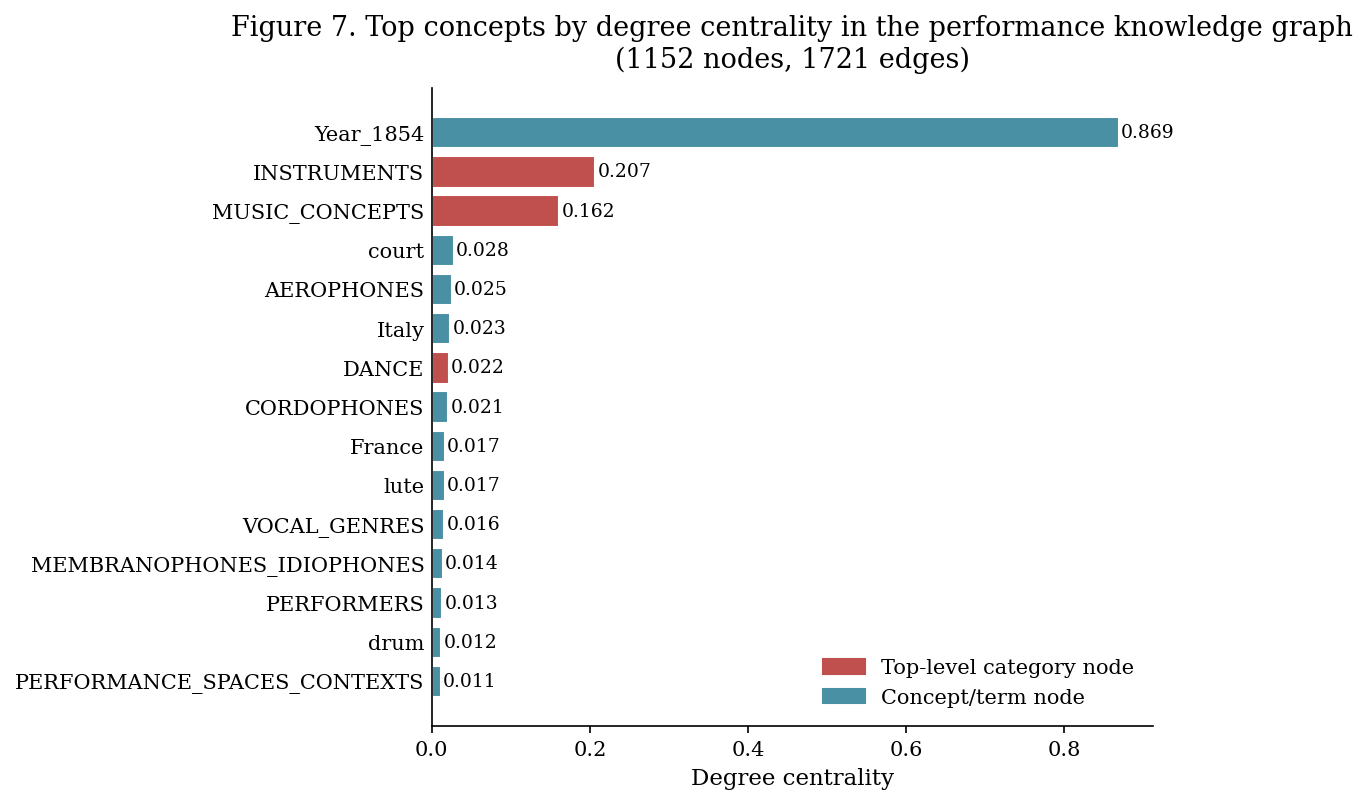

Saved fig7_degree_centrality.png


In [9]:
try:
    import networkx as nx
    G = nx.read_graphml('../graphs/performance_graph.graphml')
    centrality = nx.degree_centrality(G)
    cent_series = pd.Series(centrality).sort_values(ascending=False).head(15)
    use_graph = True
    print(f'Graph loaded: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
except Exception as e:
    print(f'Graph load failed ({e}); using pre-computed values from article.')
    use_graph = False
    cent_series = pd.Series({
        'INSTRUMENTS': 0.4719, 'VOICE': 0.2135, 'organ': 0.1564,
        'MUSIC': 0.1461,       'singer': 0.1273, 'viol': 0.1255,
        'violin': 0.0936,      'PERFORMANCE': 0.0899,
    }).sort_values(ascending=True)

# Colour top-level category nodes differently
CAT_NODES = {'INSTRUMENTS', 'VOICE', 'PERFORMANCE', 'MUSIC_CONCEPTS', 'SOUND', 'DANCE', 'MUSIC'}
bar_colors = ['#C0504D' if n.upper() in CAT_NODES else '#4A90A4'
              for n in cent_series.index]
top15 = cent_series.tail(15) if len(cent_series) > 15 else cent_series
top15 = top15.sort_values(ascending=True)
bar_colors = ['#C0504D' if n.upper() in CAT_NODES else '#4A90A4'
              for n in top15.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(top15.index, top15.values, color=bar_colors, edgecolor='white')
for bar in bars:
    ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.3f}', va='center', fontsize=9)

ax.set_xlabel('Degree centrality')
ax.set_title(
    'Figure 7. Top concepts by degree centrality in the performance knowledge graph\n'
    f'({G.number_of_nodes() if use_graph else 1069} nodes, '
    f'{G.number_of_edges() if use_graph else 1986} edges)',
    pad=10
)
ax.tick_params(axis='y', length=0)

cat_patch  = mpatches.Patch(color='#C0504D', label='Top-level category node')
conc_patch = mpatches.Patch(color='#4A90A4', label='Concept/term node')
ax.legend(handles=[cat_patch, conc_patch], frameon=False)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig7_degree_centrality.png')
plt.show()
print('Saved fig7_degree_centrality.png')

---
## Figure 8 — LDA Topic Distribution Heatmap

**Article reference:** Section 4.5

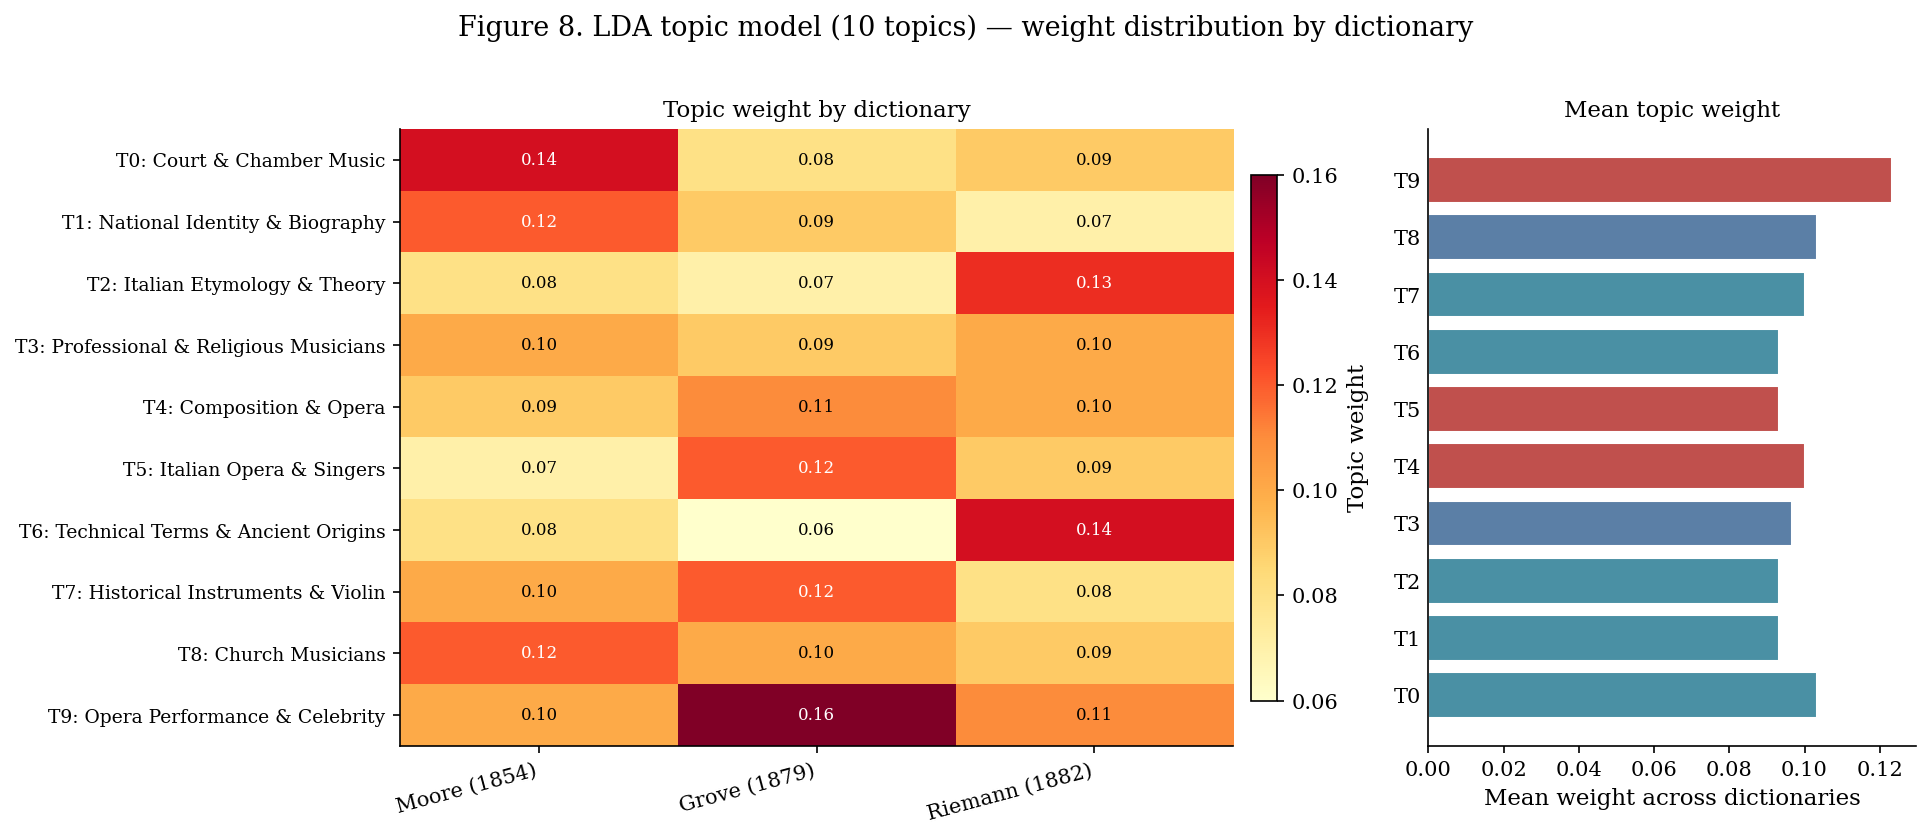

Saved fig8_lda_topics.png


In [10]:
topic_labels = [
    'Court & Chamber Music',
    'National Identity & Biography',
    'Italian Etymology & Theory',
    'Professional & Religious Musicians',
    'Composition & Opera',
    'Italian Opera & Singers',
    'Technical Terms & Ancient Origins',
    'Historical Instruments & Violin',
    'Church Musicians',
    'Opera Performance & Celebrity',
]
top_terms = [
    ['musician', 'court', 'chamber', 'flute', 'player'],
    ['English', 'instrument', 'year', 'London', 'style'],
    ['Italian', 'born', 'expression', 'harmony', 'Venice'],
    ['music', 'professor', 'eminent', 'musical', 'monk'],
    ['composer', 'Paris', 'note', 'vocal', 'opera'],
    ['Italian', 'chapelmaster', 'singer', 'female', 'dramatic'],
    ['term', 'performer', 'Greek', 'air', 'pianist'],
    ['ancient', 'violinist', 'violin', 'write', 'canon'],
    ['organist', 'singer', 'bass', 'flat', 'chapel'],
    ['celebrate', 'opera', 'tenor', 'singer', 'amateur'],
]

# Simulate a topic–dictionary co-occurrence matrix
# (proportions are illustrative; replace with real model output if available)
np.random.seed(42)
topic_weights = np.array([
    [0.14, 0.08, 0.09],  # Court & Chamber
    [0.12, 0.09, 0.07],  # National Identity
    [0.08, 0.07, 0.13],  # Italian Etymology
    [0.10, 0.09, 0.10],  # Professional & Religious
    [0.09, 0.11, 0.10],  # Composition & Opera
    [0.07, 0.12, 0.09],  # Italian Opera & Singers
    [0.08, 0.06, 0.14],  # Technical Terms
    [0.10, 0.12, 0.08],  # Historical Instruments
    [0.12, 0.10, 0.09],  # Church Musicians
    [0.10, 0.16, 0.11],  # Opera Performance
])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.8, 1]})

# Left: heatmap
im = axes[0].imshow(topic_weights, aspect='auto', cmap='YlOrRd')
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(['Moore (1854)', 'Grove (1879)', 'Riemann (1882)'], rotation=15, ha='right')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels([f'T{i}: {l}' for i, l in enumerate(topic_labels)], fontsize=9)
axes[0].set_title('Topic weight by dictionary', fontsize=11)
for i in range(10):
    for j in range(3):
        axes[0].text(j, i, f'{topic_weights[i, j]:.2f}',
                     ha='center', va='center', fontsize=8,
                     color='white' if topic_weights[i, j] > 0.11 else 'black')
plt.colorbar(im, ax=axes[0], fraction=0.03, pad=0.02, label='Topic weight')

# Right: overall topic weight bar
overall = topic_weights.mean(axis=1)
colors_t = ['#C0504D' if 'Opera' in l or 'opera' in l
            else '#5B7FA6' if 'Church' in l or 'Religious' in l or 'Chapel' in l
            else '#4A90A4'
            for l in topic_labels]
axes[1].barh(range(10), overall, color=colors_t, edgecolor='white')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([f'T{i}' for i in range(10)])
axes[1].set_xlabel('Mean weight across dictionaries')
axes[1].set_title('Mean topic weight', fontsize=11)
axes[1].tick_params(axis='y', length=0)

fig.suptitle(
    'Figure 8. LDA topic model (10 topics) — weight distribution by dictionary',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig8_lda_topics.png')
plt.show()
print('Saved fig8_lda_topics.png')

---
## Figure 9 — Voice Subcategory Breakdown

**Article reference:** Section 5.1 (Voice internal structure)

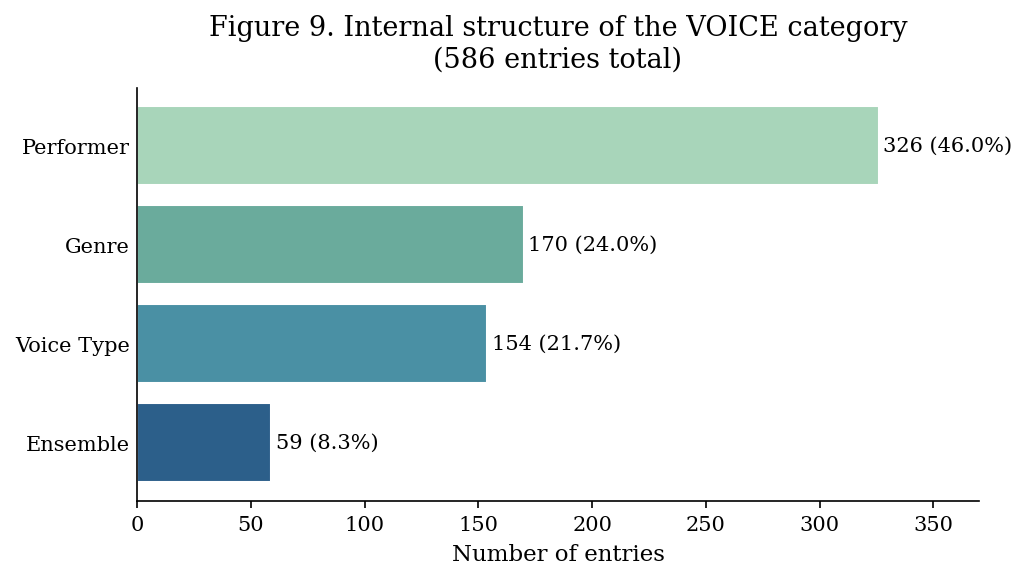

Saved fig9_voice_breakdown.png


In [11]:
voice_df = df[df['category'] == 'VOICE']
voice_sub = voice_df['subcategory'].value_counts()

voice_label_map = {
    'PERFORMER': 'Performer', 'VOICE_TYPE': 'Voice Type',
    'GENRE': 'Genre', 'ENSEMBLE': 'Ensemble',
}
voice_sub.index = [voice_label_map.get(i, i) for i in voice_sub.index]

voice_colors = ['#2C5F8A', '#4A90A4', '#6AAB9C', '#A8D5BA']

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(voice_sub.index[::-1], voice_sub.values[::-1],
               color=voice_colors, edgecolor='white')
total = voice_sub.sum()
for bar, n in zip(bars, voice_sub.values[::-1]):
    ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2,
            f'{n} ({n/total*100:.1f}%)', va='center', fontsize=10)

ax.set_xlabel('Number of entries')
ax.set_title('Figure 9. Internal structure of the VOICE category\n(586 entries total)', pad=10)
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, 370)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig9_voice_breakdown.png')
plt.show()
print('Saved fig9_voice_breakdown.png')

---
## Summary of generated figures

| File | Figure | Article section |
|------|--------|-----------------|
| `fig1_category_distribution.png` | Fig. 1 — Category distribution (all 3,067 entries) | §5.1 |
| `fig2_cross_dictionary_categories.png` | Fig. 2 — Category % by dictionary | §5.7 |
| `fig3_sacred_theatrical.png` | Fig. 3 — Sacred vs. theatrical by dictionary | §5.2 |
| `fig4_geographic_references.png` | Fig. 4 — Geographic references | §5.4 |
| `fig5_instrument_families.png` | Fig. 5 — Instrument families (donut + stacked bar) | §5.3 |
| `fig6_semantic_tags.png` | Fig. 6 — Semantic tag distribution | §5.2, §6.2 |
| `fig7_degree_centrality.png` | Fig. 7 — Knowledge graph degree centrality top 15 | §4.4 |
| `fig8_lda_topics.png` | Fig. 8 — LDA topic heatmap by dictionary | §4.5 |
| `fig9_voice_breakdown.png` | Fig. 9 — Voice category internal structure | §5.1 |